In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/housing.csv')

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [2]:
# Missing Values Analysis

missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
})

display(missing_table)

,Missing Values,Percentage
longitude,0,0.000000
latitude,0,0.000000
housing_median_age,0,0.000000
total_rooms,0,0.000000
total_bedrooms,207,1.002907
population,0,0.000000
households,0,0.000000
median_income,0,0.000000
median_house_value,0,0.000000
ocean_proximity,0,0.000000


In [3]:
# Handle Missing Values

df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

print("Missing values after imputation:")
print(df.isnull().sum().sum())

print("Dataset shape:", df.shape)

Missing values after imputation:
0
Dataset shape: (20640, 10)


In [4]:
# Outlier Detection using IQR

numeric_columns = df.select_dtypes(include=np.number).columns.drop(
    'median_house_value'
)

outlier_results = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({
        'Feature': col,
        'Outliers Count': len(outliers)
    })

iqr_results = pd.DataFrame(outlier_results)
display(iqr_results)

,Feature,Outliers Count
0,longitude,0
1,latitude,0
2,housing_median_age,0
3,total_rooms,1287
4,total_bedrooms,1306
5,population,1196
6,households,1220
7,median_income,681


In [5]:
from scipy.stats import zscore

z_scores = np.abs(zscore(df[numeric_columns]))

zscore_results = pd.DataFrame({
    'Feature': numeric_columns,
    'Outliers Count': (z_scores > 3).sum(axis=0)
})

display(zscore_results)

,Feature,Outliers Count
0,longitude,0
1,latitude,0
2,housing_median_age,0
3,total_rooms,373
4,total_bedrooms,375
5,population,342
6,households,363
7,median_income,345


In [6]:
# Outlier Treatment using IQR Capping

df_clean = df.copy()

for col in numeric_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

Original dataset shape: (20640, 10)
Cleaned dataset shape: (20640, 10)
Missing values: 0


In [7]:
from sklearn.model_selection import train_test_split

X = df_clean.drop('median_house_value', axis=1)
y = df_clean['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 9)
X_test: (4128, 9)
y_train: (16512,)
y_test: (4128,)


In [8]:
# One-Hot Encoding

X_train_encoded = pd.get_dummies(
    X_train, columns=['ocean_proximity'], drop_first=True
)

X_test_encoded = pd.get_dummies(
    X_test, columns=['ocean_proximity'], drop_first=True
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns, fill_value=0
)

print("Training features:", X_train_encoded.shape)
print("Testing features:", X_test_encoded.shape)

display(X_train_encoded.head())

Training features: (16512, 12)
Testing features: (4128, 12)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,False,False,False,True
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,False,False,False,True
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,False,False,False,True
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,False,False,False,True
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,True,False,False,False


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numeric_features = X_train_encoded.select_dtypes(
    include=np.number
).columns

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features]
)

X_test_scaled[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features]
)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

display(X_train_scaled.head())

Training data shape: (16512, 12)
Testing data shape: (4128, 12)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,1.272587,-1.372811,0.348490,0.484375,0.433900,1.257577,0.577134,-0.331680,False,False,False,True
8267,0.709162,-0.876696,1.618118,0.667355,0.993526,-0.031390,1.077901,0.000933,False,False,False,True
17445,-0.447603,-0.460146,-1.952710,-0.394072,-0.601407,-0.552990,-0.503469,0.207756,False,False,False,True
14265,1.232698,-1.382172,0.586545,-0.734300,-0.475492,0.104566,-0.431931,-1.124019,False,False,False,True
2271,-0.108551,0.532084,1.142008,-0.047410,-0.251641,-0.606588,-0.337802,-0.154455,True,False,False,False


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)

rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("--------------------------")
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

Linear Regression Results
--------------------------
RMSE: 70091.43086090892
R2 Score: 0.6250934813706363


In [11]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
---------------------
RMSE: 49213.612826540215
R2 Score: 0.8151737566166646


In [12]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'RMSE': [rmse_linear, rmse_rf],
    'R2 Score': [r2_linear, r2_rf]
})

display(comparison)

,Model,RMSE,R2 Score
0,Linear Regression,70091.430861,0.625093
1,Random Forest,49213.612827,0.815174


In [13]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Linear Regression': linear_model,
    'Random Forest': rf_model
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train_scaled,
        y_train,
        cv=kf,
        scoring={
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        }
    )

    cv_results.append({
        'Model': name,
        'Mean RMSE': -scores['test_RMSE'].mean(),
        'Mean R2': scores['test_R2'].mean()
    })

cv_comparison = pd.DataFrame(cv_results)
display(cv_comparison)

,Model,Mean RMSE,Mean R2
0,Linear Regression,66530.735751,0.668713
1,Random Forest,49591.287381,0.815991


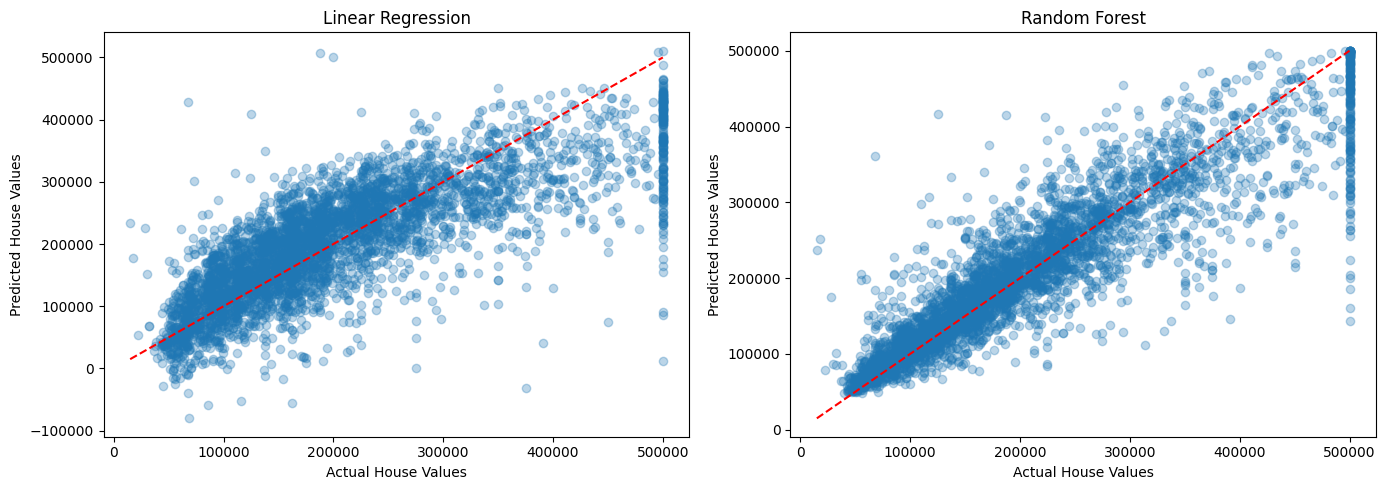

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_linear, alpha=0.3)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Actual House Values")
axes[0].set_ylabel("Predicted House Values")

axes[1].scatter(y_test, y_pred_rf, alpha=0.3)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Actual House Values")
axes[1].set_ylabel("Predicted House Values")

plt.tight_layout()
plt.show()

,Feature,Importance
7,median_income,0.488788
8,ocean_proximity_INLAND,0.141260
0,longitude,0.107487
1,latitude,0.102762
2,housing_median_age,0.052436
5,population,0.032692
3,total_rooms,0.023482
4,total_bedrooms,0.023160
6,households,0.017821
11,ocean_proximity_NEAR OCEAN,0.008875


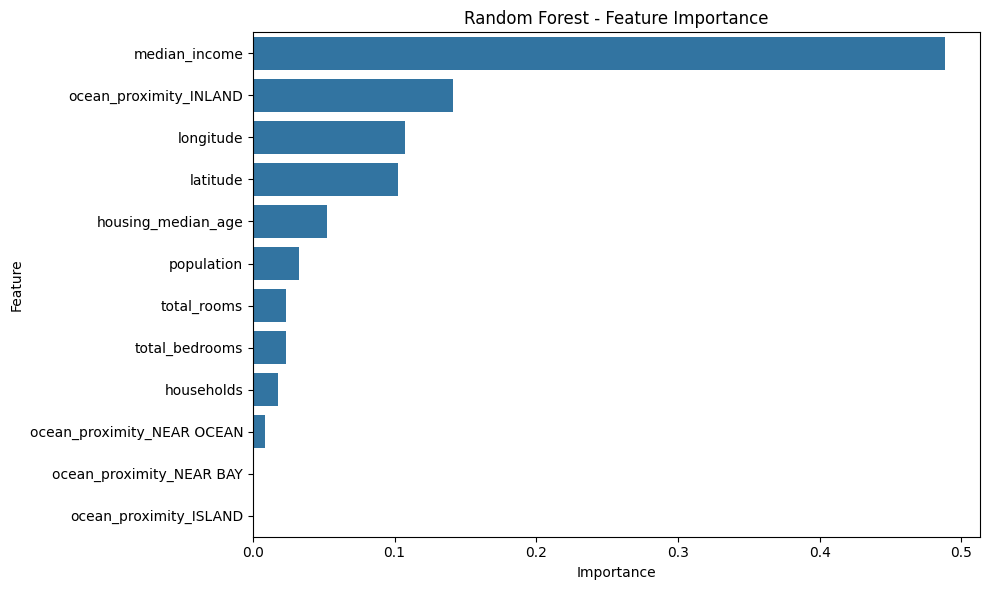

In [15]:
feature_importance = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)
plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()